# 02. Relationship Stability Diagnostics

Purely descriptive diagnostic layer: at a sequence of historical rebalance dates, every
candidate pair is re-screened using a trailing 12-month formation window, and the results are
stored longitudinally. This asks how consistently pairs satisfy the same statistical screen
across time -- independent of any trading decision. **Note:** a pair failing to qualify at a
later date is not automatically evidence of a "structural break" in the underlying relationship
-- it may equally reflect delisting, insufficient formation coverage, or the pair sitting just
outside a significance/filter threshold that quarter; the tables below report qualification
outcomes descriptively and do not attribute a cause without further breakdown. The same
significance rule frozen in notebook 01 (Engle-Granger + Benjamini-Hochberg FDR,
`CONFIG['EG_ALPHA']`) is reused verbatim.

Every statistic at rebalance date *t* uses **only** price data strictly before *t* -- the same
point-in-time constraint the walk-forward models (WF1, WF2, notebook 03) must also satisfy, so
this notebook doubles as a dry run of that logic before it is used to trade.

No new persistence methodology is introduced here (per
`docs/archive/REFACTOR_INSTRUCTIONS_CLAUDE_CODE.md` Section 6) -- this notebook reproduces the
existing, already-corrected walk-forward screen.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
for _p in (PROJECT_ROOT, PROJECT_ROOT / 'src'):
    if str(_p) not in sys.path:
        sys.path.insert(0, str(_p))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from config.research_config import (CONFIG, WF_CONFIG, MAX_HALF_LIFE_BARS, MIN_CROSSINGS, MODEL_IDS,
                                     S1_TIME_STOP_MULTIPLIER, S1_TIME_STOP_MULTIPLIER_ROBUSTNESS,
                                     FORWARD_EVAL_START)

## Walk-forward universe: WF_PX / WF_RET

A **separately rebuilt** universe (45 coins), not notebook 01's statically-filtered `px`/`ret`
(28 coins). `WF_CONFIG['MANUAL_EXCLUDE']` only drops true stablecoins -- unlike the static
universe, XMR and every coin dropped via the one-time `MIN_HISTORY_CUTOFF` are included, since
point-in-time coverage + active-at-rebalance eligibility is designed to handle late
listings/delistings correctly without a manual cutoff.

In [2]:
from stat_arb.data import build_walkforward_universe

WF_PX, WF_RET = build_walkforward_universe(WF_CONFIG)
print(f'Walk-forward universe: {WF_PX.shape[1]} coins')
assert 'XMRUSDT' in WF_PX.columns, 'XMR must be present in the walk-forward universe.'

Walk-forward universe: 45 coins


In [3]:
from stat_arb.walkforward import generate_rebalance_dates

REBALANCE_DATES = generate_rebalance_dates(CONFIG['FORMATION_START'], CONFIG['OOS_END'],
                                            spacing_months=WF_CONFIG['REBALANCE_MONTHS_PRIMARY'],
                                            min_formation_months=WF_CONFIG['FORMATION_MONTHS'])
print(f'{len(REBALANCE_DATES)} historical rebalance dates (12-month trailing formation, 6-month spacing):')
print([d.date() for d in REBALANCE_DATES])

11 historical rebalance dates (12-month trailing formation, 6-month spacing):
[datetime.date(2021, 1, 1), datetime.date(2021, 7, 1), datetime.date(2022, 1, 1), datetime.date(2022, 7, 1), datetime.date(2023, 1, 1), datetime.date(2023, 7, 1), datetime.date(2024, 1, 1), datetime.date(2024, 7, 1), datetime.date(2025, 1, 1), datetime.date(2025, 7, 1), datetime.date(2026, 1, 1)]


### Longitudinal Pair-Stability Dataset

This screen is expensive (~1,600+ directional Engle-Granger tests per rebalance date x 11
dates), so it is precomputed via a standalone resumable script
(`scripts/run_stability_screen.py`) that imports `screen_pairs_at_date` from
`stat_arb.pair_selection` directly (no forked copy), cached to disk keyed by the full
methodology fingerprint below. This cell only loads the cache; it asserts loudly (with the
expected path) if the cache is missing rather than silently recomputing on a hot path.

In [4]:
from stat_arb.cache import wf_cache_fingerprint, load_or_assert, cache_path

stability_fingerprint = wf_cache_fingerprint(universe_cols=WF_PX.columns, rebalance_dates=REBALANCE_DATES, wf_config=WF_CONFIG)
stability_cache_path = cache_path('pair_stability', stability_fingerprint)

pair_stability_df = load_or_assert(
    stability_cache_path,
    f'Stability cache not found at {stability_cache_path}. Regenerate via scripts/run_stability_screen.py.')
print(f'Loaded pair-stability diagnostic (fingerprint {stability_fingerprint}): '
      f'{pair_stability_df.shape[0]} (pair, date) rows across {pair_stability_df["rebalance_date"].nunique()} rebalance dates')
pair_stability_df.groupby('rebalance_date').size().rename('n_qualifying_pairs')

Loaded pair-stability diagnostic (fingerprint 523179f2a1): 26 (pair, date) rows across 5 rebalance dates


rebalance_date
2021-07-01     1
2022-01-01     3
2022-07-01     3
2023-07-01     4
2024-01-01    15
Name: n_qualifying_pairs, dtype: int64

### Persistence, Drift, and Qualification Diagnostics

In [5]:
qual_freq = pair_stability_df.groupby('pair')['rebalance_date'].nunique().sort_values(ascending=False)
print('Qualification frequency (number of rebalance dates each pair qualified at):')
qual_freq

Qualification frequency (number of rebalance dates each pair qualified at):


pair
(AAVEUSDT, AVAXUSDT)    1
(AAVEUSDT, DOTUSDT)     1
(AAVEUSDT, VETUSDT)     1
(ADAUSDT, LDOUSDT)      1
(APTUSDT, LDOUSDT)      1
(ATOMUSDT, FTMUSDT)     1
(ATOMUSDT, LDOUSDT)     1
(AVAXUSDT, LDOUSDT)     1
(BNBUSDT, LDOUSDT)      1
(DOGEUSDT, LDOUSDT)     1
(DOTUSDT, LDOUSDT)      1
(FILUSDT, LDOUSDT)      1
(FTMUSDT, LDOUSDT)      1
(GRTUSDT, INJUSDT)      1
(ICPUSDT, LDOUSDT)      1
(IMXUSDT, LDOUSDT)      1
(INJUSDT, LTCUSDT)      1
(LDOUSDT, NEARUSDT)     1
(LDOUSDT, OMUSDT)       1
(LDOUSDT, SHIBUSDT)     1
(LDOUSDT, UNIUSDT)      1
(LDOUSDT, VETUSDT)      1
(LINKUSDT, XLMUSDT)     1
(LTCUSDT, XLMUSDT)      1
(MKRUSDT, XMRUSDT)      1
(VETUSDT, XLMUSDT)      1
Name: rebalance_date, dtype: int64

Pairs qualifying at 2+ rebalance dates: 0 of 26 total qualifying pairs


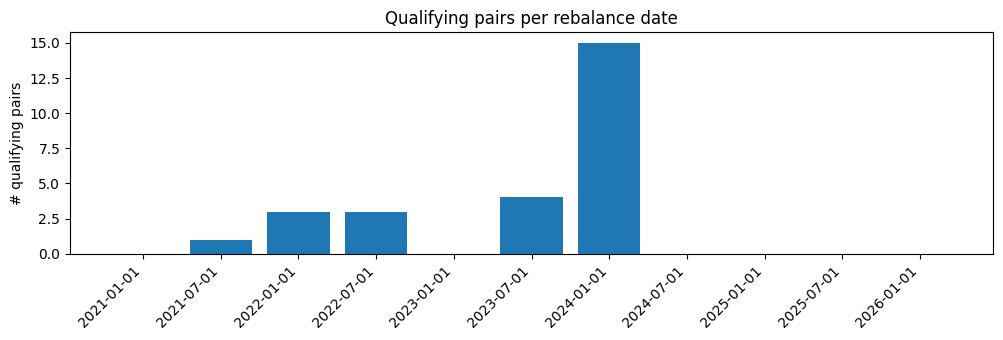

In [6]:
pivot_qual = pair_stability_df.pivot_table(index='pair', columns='rebalance_date', values='eg_pvalue', aggfunc='first').notna()
recurring_pairs = pivot_qual.index[pivot_qual.sum(axis=1) >= 2]
print(f'Pairs qualifying at 2+ rebalance dates: {len(recurring_pairs)} of {len(pivot_qual)} total qualifying pairs')

n_qualifying_by_date = pair_stability_df.groupby('rebalance_date').size().reindex(REBALANCE_DATES, fill_value=0)
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar([d.date().isoformat() for d in n_qualifying_by_date.index], n_qualifying_by_date.values)
ax.set_ylabel('# qualifying pairs')
ax.set_title('Qualifying pairs per rebalance date')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [7]:
if len(recurring_pairs):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for pair in recurring_pairs:
        sub = pair_stability_df[pair_stability_df['pair'] == pair].sort_values('rebalance_date')
        axes[0].plot(sub['rebalance_date'], sub['beta'], marker='o', label=f'{pair[0]}/{pair[1]}')
        axes[1].plot(sub['rebalance_date'], sub['half_life_bars'], marker='o', label=f'{pair[0]}/{pair[1]}')
    axes[0].set_title('Beta evolution (recurring pairs)')
    axes[1].set_title('Half-life evolution (recurring pairs)')
    for ax in axes:
        ax.legend(fontsize=7)
        ax.tick_params(axis='x', rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print('No pair qualifies at 2+ rebalance dates -- no persistence chart to draw.')

No pair qualifies at 2+ rebalance dates -- no persistence chart to draw.


## Interpretation

Very few pairs qualify at any given rebalance date under the corrected point-in-time
methodology (coverage, active-at-rebalance, matching S0's half-life/crossing/positive-Beta
filters), and qualification is highly discontinuous across dates rather than persistent. This
motivates treating WF1/WF2's low trade counts (notebook 03) as a first-order caveat, not a
detail.